<a href="https://www.kaggle.com/code/shedai/hermai-test?scriptVersionId=265231607" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
# HÜCRE 1: Kütüphaneyi GitHub'daki belirli bir release'den kurma
# En son çalışan versiyon etiketini kullandığınızdan emin olun.
print("⏳ Hermai kütüphanesi kuruluyor...")
!pip install hermai
print("✅ Kurulum tamamlandı. Lütfen bir sonraki adıma geçmeden önce oturumu yeniden başlatın.")

⏳ Hermai kütüphanesi kuruluyor...
✅ Kurulum tamamlandı. Lütfen bir sonraki adıma geçmeden önce oturumu yeniden başlatın.


In [3]:
# HÜCRE 2: Teşhis Komutları

# 1. Python'un paketleri aradığı ana klasörün içeriğini listeleyelim.
# Bu çıktıda "hermai" adında bir klasör görmeliyiz.
print("--- Site-Packages Klasör İçeriği ---")
!ls -l /usr/local/lib/python3.12/dist-packages/

# 2. pip'e, "hermai" paketinin kurulu olup olmadığını ve nereye kurulduğunu soralım.
print("\n--- 'pip show hermai' Çıktısı ---")
!pip show hermai

--- Site-Packages Klasör İçeriği ---
ls: cannot access '/usr/local/lib/python3.12/dist-packages/': No such file or directory

--- 'pip show hermai' Çıktısı ---
Name: hermai
Version: 0.1.8
Summary: A hermeneutic approach to explainable AI (XAI) with contextual and narrative explanations.
Home-page: https://github.com/bilgisayarkavramlari/hermai
Author: sadi evren seker
Author-email: hermai@sadievrenseker.com
License: 
Location: /usr/local/lib/python3.11/dist-packages
Requires: matplotlib, numpy, pandas, scikit-learn, seaborn
Required-by: 


In [4]:
# HÜCRE 3: Son Test (Yeniden başlattıktan sonra)
import sys
# Python'un paket arama yollarını görelim
print("Python Path:", sys.path)

# Import etmeyi deneyelim
try:
    from hermai.explainers import LocalExplainer
    print("\n✅ BAŞARILI: 'hermai' modülü başarıyla import edildi!")
except ModuleNotFoundError as e:
    print(f"\n❌ HATA: Modül hala bulunamadı. Hata: {e}")

Python Path: ['/kaggle/working', '/kaggle/lib/kagglegym', '/kaggle/lib', '/usr/lib/python311.zip', '/usr/lib/python3.11', '/usr/lib/python3.11/lib-dynload', '', '/usr/local/lib/python3.11/dist-packages', '/usr/lib/python3/dist-packages', '/usr/local/lib/python3.11/dist-packages/IPython/extensions', '/usr/local/lib/python3.11/dist-packages/setuptools/_vendor', '/root/.ipython']

✅ BAŞARILI: 'hermai' modülü başarıyla import edildi!


✅ Hermai ve diğer kütüphaneler başarıyla import edildi!

🚢 Veri yükleniyor ve model eğitiliyor...


/tmp/ipykernel_13/2237353199.py:20: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace=True)
/tmp/ipykernel_13/2237353199.py:21: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

   - Model doğruluğu: 0.82


🔬 Lokal Açıklama Testi...

--- Açıklama Metni ---
Prediction Analysis for Instance:
---------------------------------
Model predicted class '0' with 3.00% confidence.

Key Feature Contributions (Local Importance):
- Feature 'sex' decreases the probability.
- Feature 'age' decreases the probability.
- Feature 'fare' increases the probability.
- Feature 'sibsp' decreases the probability.
- Feature 'pclass' decreases the probability.

Counterfactual Analysis:
To flip the prediction to class '1', one of the closest possibilities found is:
- Change 'pclass' from 2.00 to 3.00
- Change 'age' from 31.00 to 26.57
- Change 'sibsp' from 0.00 to 0.17
- Change 'parch' from 0.00 to -0.17
- Change 'fare' from 10.50 to 5.35


--- Özellik Katkı Grafiği ---


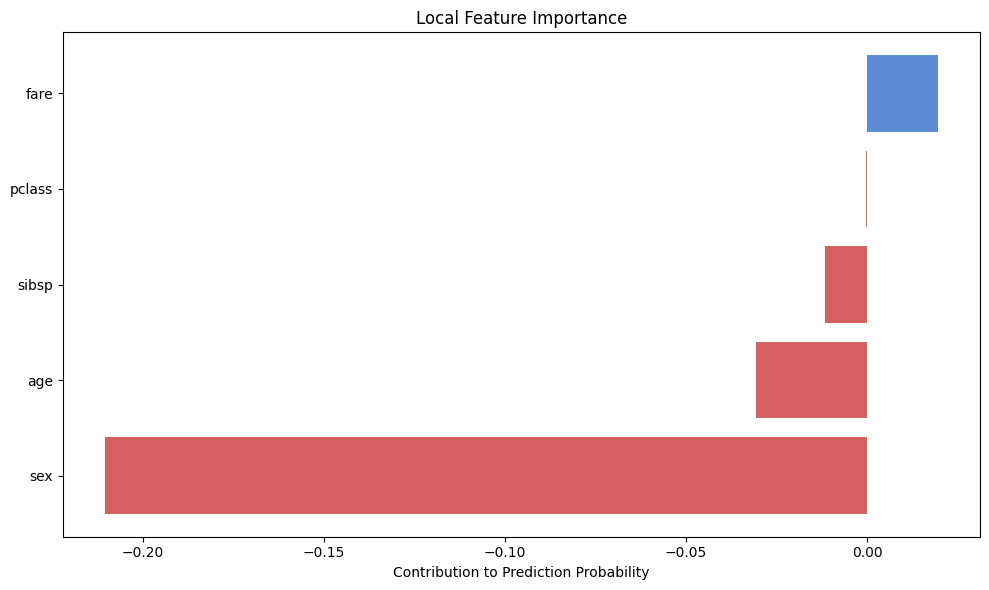



🌍 Genel Model Açıklaması Testi...

--- Genel Özellik Önem Grafiği ---


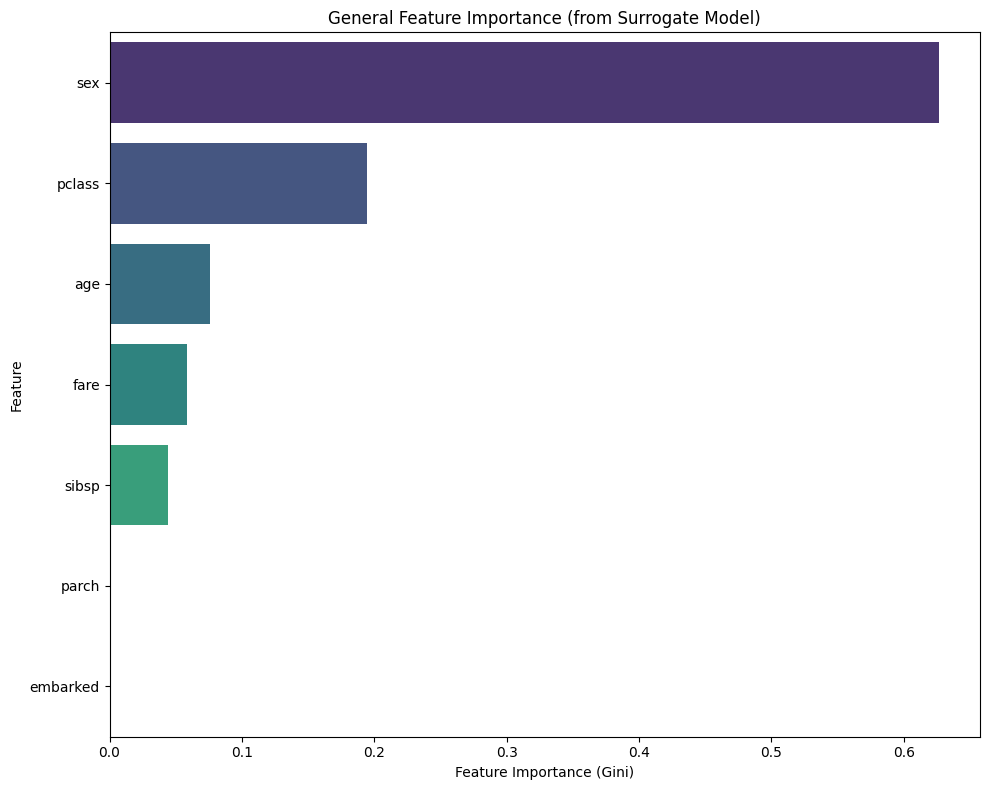


--- Yaklaşık Karar Kuralları (Vekil Ağaç) ---


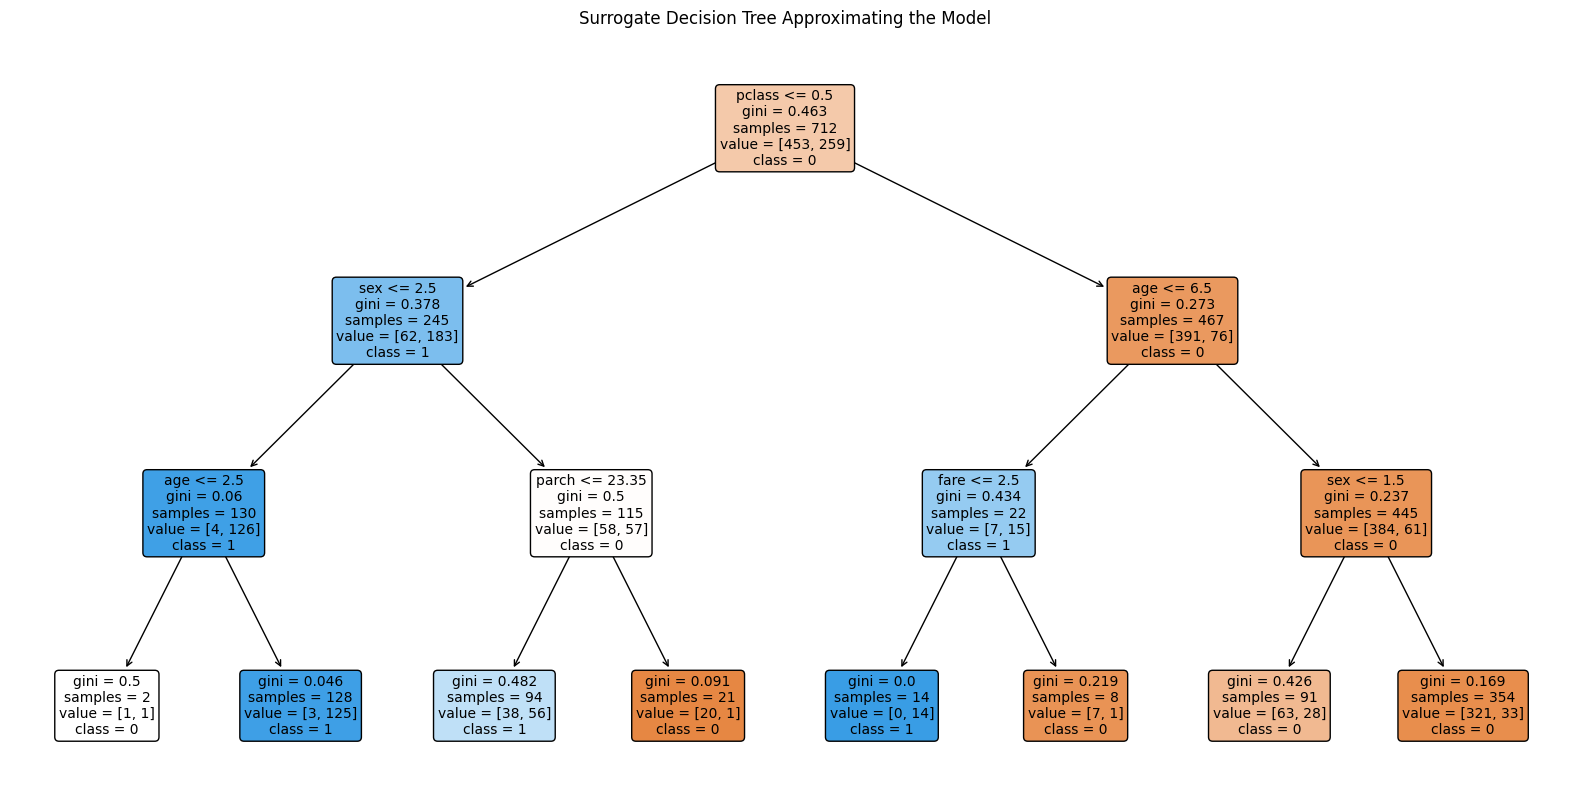

In [5]:
# HÜCRE 2: Gerekli kütüphaneleri ve Hermai'yi import etme
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

# Kendi kütüphanemizi import edelim
from hermai.perturbations.tabular import TabularPerturbationGenerator
from hermai.explainers import LocalExplainer, GeneralExplainer

print("✅ Hermai ve diğer kütüphaneler başarıyla import edildi!")

# --- Veri Yükleme ve Model Eğitme ---
print("\n🚢 Veri yükleniyor ve model eğitiliyor...")
# Veri setini yüklerken oluşabilecek 'FutureWarning' uyarısını bastırmak için:
pd.set_option('future.no_silent_downcasting', True)
df = sns.load_dataset('titanic').drop(['deck', 'embark_town', 'alive', 'who', 'adult_male', 'alone', 'class'], axis=1)
df['age'].fillna(df['age'].median(), inplace=True)
df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)
df.dropna(inplace=True)
df['sex'] = LabelEncoder().fit_transform(df['sex'])
df['embarked'] = LabelEncoder().fit_transform(df['embarked'])
X, y = df.drop('survived', axis=1), df['survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

black_box_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
print(f"   - Model doğruluğu: {black_box_model.score(X_test, y_test):.2f}")


# --- Lokal Açıklama Üretme ve Test Etme ---
print("\n\n🔬 Lokal Açıklama Testi...")
generator = TabularPerturbationGenerator(categorical_features=['pclass', 'sex', 'embarked'])
generator.fit(X_train)
local_explainer = LocalExplainer(black_box_model, generator)
instance = X_test.iloc[1]

local_explanation = local_explainer.explain(instance)

print("\n--- Açıklama Metni ---")
print(local_explanation.narrative())

print("\n--- Özellik Katkı Grafiği ---")
local_explanation.plot()
plt.show() # Colab'de grafiği göstermek için


# --- Genel Model Açıklaması Üretme ve Test Etme ---
print("\n\n🌍 Genel Model Açıklaması Testi...")
general_explainer = GeneralExplainer(black_box_model)
general_explanation = general_explainer.explain(X_train)

print("\n--- Genel Özellik Önem Grafiği ---")
general_explanation.plot_feature_importance()
plt.show()

print("\n--- Yaklaşık Karar Kuralları (Vekil Ağaç) ---")
general_explanation.plot_surrogate_tree()
plt.show()